# 03 - Baselines and models

Compares simple baselines against logistic regression and gradient-boosted trees (and, optionally, a small neural network) for the chase win probability, then chooses the final model and feature set.

**Inputs:** your train and validation feature files (from your split of `features_all.csv`) and `feature_groups.json`.
**Outputs (in `OUT_DIR`):** metric tables, calibration and by-over figures, `val_predictions.csv`, and `model_selection.json` (read by the final-test notebook).

Rules this notebook follows
1. **The test seasons are never loaded.** It stops if either file contains a season from `TEST_START_SEASON` onwards.
2. **Tuning uses grouped cross-validation on the training seasons** (all rows of a match stay in one fold). The 2024 validation season is only used to compare candidates.
3. **Preprocessing lives inside the pipelines**, so imputation and scaling are fitted on training rows only (and refitted inside every fold).
4. **Gradient boosting uses `early_stopping=False`.** Its built-in early stopping splits by row, which would put rows of the same match on both sides.
5. **The choice of final model is made here**, with a rule fixed in advance (see section 12), and written to disk.

## 1. Settings (edit the paths)

In [1]:
TRAIN_PATH  = r"../data/split/train.csv"            # your training split (e.g. seasons 2017-2023)
VAL_PATH    = r"../data/split/validation.csv"              # your validation split (e.g. season 2024)
GROUPS_PATH = r"../data/features/feature_groups.json"
OUT_DIR     = r"../results"

TEST_START_SEASON = 2025        # first test season; the notebook refuses any row at or after it
MAIN_GROUPS = ["core", "derived", "momentum"]   # the feature groups of the main model
N_FOLDS = 5                     # grouped cross-validation folds (groups = matches)
N_BOOT = 2000                   # bootstrap resamples of whole matches
RUN_MLP = True                  # the optional small neural network
TOL = 0.003                     # selection rule: simplest candidate within this log loss of the best
RANDOM_STATE = 0

## 2. Load the data (with the test-set guard)

In [2]:
import json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
import sklearn
from sklearn.base import clone
from sklearn.calibration import calibration_curve
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.impute import SimpleImputer
from sklearn.isotonic import IsotonicRegression
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, GroupKFold, cross_val_predict
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
warnings.filterwarnings("ignore", category=ConvergenceWarning)

LABEL = "chasing_team_won"
GROUPS = json.loads(Path(GROUPS_PATH).read_text())
ALL_FEATURES = [f for g in GROUPS.values() for f in g]
MAIN = [f for g in MAIN_GROUPS for f in GROUPS[g]]
out = Path(OUT_DIR); out.mkdir(parents=True, exist_ok=True)

def load(path, name):
    df = pd.read_csv(path, dtype={"match_id": str})
    need = ["match_id", "season", "over", LABEL] + ALL_FEATURES
    missing = [c for c in need if c not in df.columns]
    assert not missing, f"{name} file is missing columns: {missing}"
    assert df.season.max() < TEST_START_SEASON, (
        f"{name} file contains season {df.season.max()}, which is a test season "
        f"(>= {TEST_START_SEASON}). This notebook must not use test data - check the path.")
    return df

train, val = load(TRAIN_PATH, "train"), load(VAL_PATH, "val")
assert not set(train.match_id) & set(val.match_id), "a match appears in both train and validation"
assert train.season.max() < val.season.min(), "training seasons must come before the validation seasons"
y_tr, y_va = train[LABEL].to_numpy(), val[LABEL].to_numpy()
groups_tr = train.match_id.to_numpy()

print(f"scikit-learn {sklearn.__version__}")
print(f"train: seasons {train.season.min()}-{train.season.max()}, {train.match_id.nunique()} matches, {len(train)} rows, chase win rate {y_tr.mean():.3f} per row")
print(f"val:   seasons {val.season.min()}-{val.season.max()}, {val.match_id.nunique()} matches, {len(val)} rows, chase win rate {y_va.mean():.3f} per row")
print(f"main model uses {len(MAIN)} features: {MAIN}")

scikit-learn 1.9.0
train: seasons 2008-2023, 977 matches, 17578 rows, chase win rate 0.526 per row
val:   seasons 2024-2024, 70 matches, 1239 rows, chase win rate 0.487 per row
main model uses 15 features: ['runs_so_far', 'target', 'wickets_lost', 'balls_left', 'current_run_rate', 'required_run_rate', 'run_rate_diff', 'runs_needed_frac', 'resources', 'runs_needed_per_wicket', 'runs_last_3', 'wkts_last_3', 'boundaries_last_3', 'acceleration', 'balls_since_last_wicket']


## 3. Metrics

- **Log loss** (main): penalises confident wrong probabilities heavily; the right metric when the output is a probability.
- **Brier score:** mean squared error of the probability.
- **Accuracy:** shown but secondary. Late-over states are nearly decided, so overall accuracy flatters every model.

Probabilities are clipped to [1e-6, 1 - 1e-6] so a single extreme prediction can't produce an infinite loss.

In [3]:
EPS = 1e-6
def clip(p):
    return np.clip(np.asarray(p, dtype=float), EPS, 1 - EPS)

def row_loss(y, p):
    p = clip(p)
    return -(y * np.log(p) + (1 - y) * np.log(1 - p))

def summarize(y, p):
    p = clip(p)
    return {"log_loss": row_loss(y, p).mean(), "brier": np.mean((p - y) ** 2), "accuracy": np.mean((p >= 0.5) == y)}

def report(preds, y=None):
    y = y_va if y is None else y
    return pd.DataFrame({k: summarize(y, p) for k, p in preds.items()}).T.round(4)

def by_over(y, p, over):
    d = pd.DataFrame({"over": over, "loss": row_loss(y, p), "correct": (clip(p) >= 0.5) == y})
    return d.groupby("over").agg(log_loss=("loss", "mean"), accuracy=("correct", "mean"), rows=("loss", "size"))

## 4. Baselines

| Baseline | What it does |
|---|---|
| **A** | Always predicts the chase win rate of the training rows (per row, not per match, because the model is scored per row). |
| **A2** | Predicts the training win rate for each over number: it knows the time but not the match state. |
| **B** | The cricket rule "the chasing team wins if its current run rate is at least the required rate", turned into probabilities with two numbers fitted on the training seasons: the win rate among rows where the rule says "win" and where it says "lose". |

A model has to beat **B** to show that machine learning adds something beyond the textbook rule.

In [4]:
p_const = y_tr.mean()
rate_by_over = train.groupby("over")[LABEL].mean()
rule_tr = (train.run_rate_diff <= 0)                   # current run rate >= required run rate
p_rule_win, p_rule_lose = y_tr[rule_tr].mean(), y_tr[~rule_tr].mean()
print(f"B: P(win | rule says win) = {p_rule_win:.3f}, P(win | rule says lose) = {p_rule_lose:.3f}")

preds = {
    "A  constant (train win rate)": np.full(len(val), p_const),
    "A2 win rate by over": val.over.map(rate_by_over).fillna(p_const).to_numpy(),
    "B  rule: current >= required": np.where(val.run_rate_diff <= 0, p_rule_win, p_rule_lose),
}
report(preds)

B: P(win | rule says win) = 0.851, P(win | rule says lose) = 0.370


,log_loss,brier,accuracy
A constant (train win rate),0.6958,0.2513,0.4875
A2 win rate by over,0.6923,0.2496,0.5077
B rule: current >= required,0.5522,0.1838,0.7595


## 5. Logistic regression

A regularised linear model on the standardised features. `C` is the inverse regularisation strength (smaller = stronger). It is chosen by grouped cross-validation on the training seasons only.

In [5]:
def make_preprocessor(cols):
    return ColumnTransformer([("num", Pipeline([("impute", SimpleImputer(strategy="median")),
                                                ("scale", StandardScaler())]), cols)])

def make_logreg(cols, C=1.0):
    return Pipeline([("pre", make_preprocessor(cols)), ("clf", LogisticRegression(C=C, max_iter=5000))])

cv = GroupKFold(n_splits=N_FOLDS)
gs_lr = GridSearchCV(make_logreg(MAIN), {"clf__C": np.logspace(-3, 2, 11)}, cv=cv, scoring="neg_log_loss")
gs_lr.fit(train[MAIN], y_tr, groups=groups_tr)
best_C = gs_lr.best_params_["clf__C"]
print(f"best C = {best_C:.4g}, grouped-CV log loss = {-gs_lr.best_score_:.4f}")

lr = gs_lr.best_estimator_
preds["LR  logistic regression"] = lr.predict_proba(val[MAIN])[:, 1]

coefs = pd.Series(lr.named_steps["clf"].coef_[0], index=MAIN).sort_values()
coefs.round(3).to_frame("standardised coefficient")

best C = 0.1, grouped-CV log loss = 0.4374


,standardised coefficient
runs_needed_per_wicket,-0.953
required_run_rate,-0.901
run_rate_diff,-0.720
runs_needed_frac,-0.605
wickets_lost,-0.580
target,-0.259
current_run_rate,-0.253
runs_last_3,-0.146
balls_since_last_wicket,-0.099
wkts_last_3,-0.094


## 6. Gradient-boosted trees

Trees can capture interactions such as "40 needed off 24 balls means something different with 2 wickets lost than with 8" without hand-made terms. A small grid is tuned with the same grouped folds. Number of trees (`max_iter`) is part of the grid because built-in early stopping is switched off.

A second version adds **monotonic constraints** (win probability may never rise as wickets lost, required run rate, run-rate gap, runs needed per wicket or the runs-needed fraction rise), re-using the tuned settings. That keeps the model cricket-sensible.

In [6]:
def make_hgb(**kw):
    return HistGradientBoostingClassifier(early_stopping=False, random_state=RANDOM_STATE, **kw)

grid = {"learning_rate": [0.03, 0.1], "max_depth": [2, 3, 4], "max_iter": [100, 300],
        "min_samples_leaf": [20, 60], "l2_regularization": [0.0, 1.0]}
gs_hgb = GridSearchCV(make_hgb(), grid, cv=cv, scoring="neg_log_loss", n_jobs=-1)
gs_hgb.fit(train[MAIN], y_tr, groups=groups_tr)
best_hgb_params = gs_hgb.best_params_
print("best settings:", best_hgb_params, f"| grouped-CV log loss = {-gs_hgb.best_score_:.4f}")

hgb = gs_hgb.best_estimator_
preds["HGB gradient-boosted trees"] = hgb.predict_proba(val[MAIN])[:, 1]

MONO = {"wickets_lost": -1, "required_run_rate": -1, "run_rate_diff": -1,
        "runs_needed_frac": -1, "runs_needed_per_wicket": -1}
hgb_mono = make_hgb(**best_hgb_params, monotonic_cst=[MONO.get(f, 0) for f in MAIN]).fit(train[MAIN], y_tr)
preds["HGBm gradient-boosted, monotonic"] = hgb_mono.predict_proba(val[MAIN])[:, 1]

cvr = pd.DataFrame(gs_hgb.cv_results_)[["params", "mean_test_score", "std_test_score"]]
cvr["cv_log_loss"] = -cvr.mean_test_score
cvr.sort_values("cv_log_loss").head(5)[["params", "cv_log_loss", "std_test_score"]]

best settings: {'l2_regularization': 0.0, 'learning_rate': 0.03, 'max_depth': 2, 'max_iter': 300, 'min_samples_leaf': 60} | grouped-CV log loss = 0.4434


,params,cv_log_loss,std_test_score
3,"{'l2_regularization': 0.0, 'learning_rate': 0....",0.443405,0.026755
36,"{'l2_regularization': 1.0, 'learning_rate': 0....",0.443455,0.026461
2,"{'l2_regularization': 0.0, 'learning_rate': 0....",0.443538,0.026618
26,"{'l2_regularization': 1.0, 'learning_rate': 0....",0.443539,0.026365
27,"{'l2_regularization': 1.0, 'learning_rate': 0....",0.443590,0.026372


## 7. Optional: a small neural network

Included only to check whether it beats boosting on this tabular data. I don't assume it will.

In [7]:
if RUN_MLP:
    mlp_pipe = Pipeline([("pre", make_preprocessor(MAIN)),
                         ("clf", MLPClassifier(max_iter=800, early_stopping=False, random_state=RANDOM_STATE))])
    mlp_grid = {"clf__hidden_layer_sizes": [(16,), (32, 16)], "clf__alpha": [1e-3, 1e-2, 1e-1]}
    gs_mlp = GridSearchCV(mlp_pipe, mlp_grid, cv=cv, scoring="neg_log_loss", n_jobs=-1)
    gs_mlp.fit(train[MAIN], y_tr, groups=groups_tr)
    print("best settings:", gs_mlp.best_params_, f"| grouped-CV log loss = {-gs_mlp.best_score_:.4f}")
    preds["MLP small neural network"] = gs_mlp.best_estimator_.predict_proba(val[MAIN])[:, 1]
else:
    print("RUN_MLP is False: skipped")

best settings: {'clf__alpha': 0.1, 'clf__hidden_layer_sizes': (16,)} | grouped-CV log loss = 0.4437


## 8. Validation comparison

Every model against the baselines on the 2024 validation season. The bootstrap resamples **whole matches** (rows of one match are not independent), so the intervals are honest about how few matches there are. The `diff` columns are paired differences from baseline B: **negative means better than the rule**.

In [8]:
def per_match(loss, match_ids):
    g = pd.DataFrame({"m": match_ids, "l": loss}).groupby("m").l.agg(["sum", "count"])
    return g["sum"].to_numpy(), g["count"].to_numpy()

def bootstrap(preds, y, match_ids, reference, B=N_BOOT, seed=0):
    rng = np.random.default_rng(seed)
    arrs = {k: per_match(row_loss(y, p), match_ids) for k, p in preds.items()}
    M = len(arrs[reference][0])
    idx = rng.integers(0, M, size=(B, M))
    ref = arrs[reference][0][idx].sum(1) / arrs[reference][1][idx].sum(1)
    rows = {}
    for k, (s, n) in arrs.items():
        ll = s[idx].sum(1) / n[idx].sum(1)
        diff = ll - ref
        rows[k] = {"log_loss": s.sum() / n.sum(),
                   "95% CI": f"[{np.percentile(ll, 2.5):.4f}, {np.percentile(ll, 97.5):.4f}]",
                   "diff vs B": diff.mean() if k != reference else np.nan,
                   "diff 95% CI": f"[{np.percentile(diff, 2.5):.4f}, {np.percentile(diff, 97.5):.4f}]" if k != reference else "",
                   "P(better than B)": (diff < 0).mean() if k != reference else np.nan}
    return pd.DataFrame(rows).T

REF = "B  rule: current >= required"
table = report(preds).join(bootstrap(preds, y_va, val.match_id.to_numpy(), REF).drop(columns="log_loss"))
table.to_csv(out / "validation_table.csv")
table

,log_loss,brier,accuracy,95% CI,diff vs B,diff 95% CI,P(better than B)
A constant (train win rate),0.6958,0.2513,0.4875,"[0.6835, 0.7075]",0.144015,"[0.0868, 0.2005]",0.0
A2 win rate by over,0.6923,0.2496,0.5077,"[0.6795, 0.7045]",0.140472,"[0.0841, 0.1965]",0.0
B rule: current >= required,0.5522,0.1838,0.7595,"[0.4927, 0.6112]",NaN,,NaN
LR logistic regression,0.3765,0.1206,0.8241,"[0.2864, 0.4851]",-0.17488,"[-0.2637, -0.0760]",1.0
HGB gradient-boosted trees,0.3816,0.1221,0.8337,"[0.2844, 0.4992]",-0.169183,"[-0.2653, -0.0548]",0.9975
"HGBm gradient-boosted, monotonic",0.3806,0.1218,0.8362,"[0.2838, 0.4973]",-0.170156,"[-0.2657, -0.0557]",0.9975
MLP small neural network,0.3827,0.1231,0.8281,"[0.2813, 0.5073]",-0.168512,"[-0.2683, -0.0516]",0.9975


## 9. Calibration and performance by over

A well-calibrated model that says 70% should be right about 70% of the time. The left plot compares predicted probability with the observed win rate (closer to the diagonal is better). The right plot shows log loss by over: early overs should be close to chance, late overs much easier.

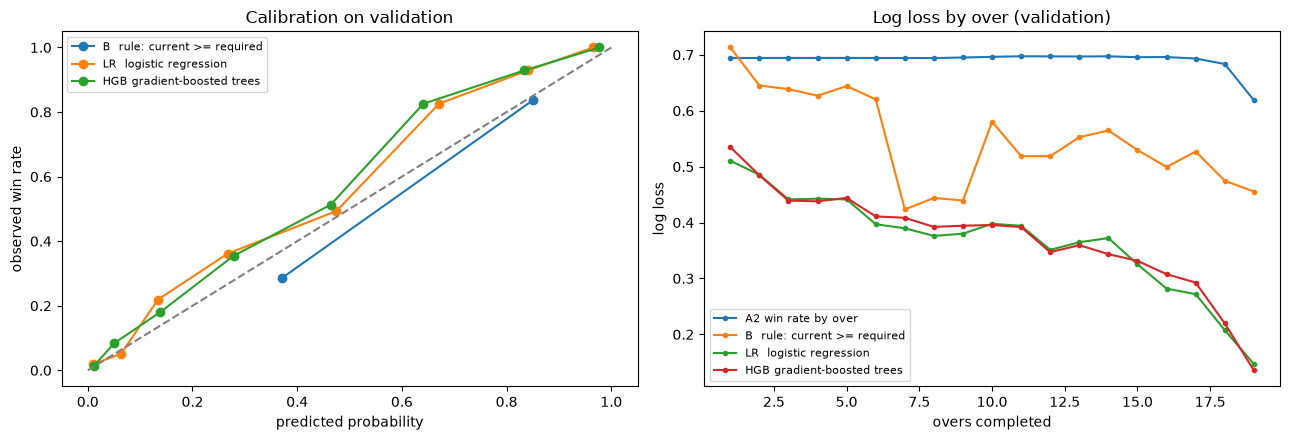

In [9]:
show = ["B  rule: current >= required", "LR  logistic regression", "HGB gradient-boosted trees"]
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for k in show:
    frac, mean_p = calibration_curve(y_va, clip(preds[k]), n_bins=8, strategy="quantile")
    ax[0].plot(mean_p, frac, marker="o", label=k)
ax[0].plot([0, 1], [0, 1], ls="--", c="gray")
ax[0].set(title="Calibration on validation", xlabel="predicted probability", ylabel="observed win rate")
ax[0].legend(fontsize=8)
for k in ["A2 win rate by over"] + show:
    bo = by_over(y_va, preds[k], val.over.to_numpy())
    ax[1].plot(bo.index, bo.log_loss, marker=".", label=k)
ax[1].set(title="Log loss by over (validation)", xlabel="overs completed", ylabel="log loss")
ax[1].legend(fontsize=8)
fig.tight_layout(); fig.savefig(out / "calibration_and_by_over.png", dpi=120); plt.show()

## 10. Does recalibration help?

If a model is miscalibrated, a small correction can fix it. The correction is fitted on **out-of-fold predictions from the training seasons** (grouped by match), so the validation labels stay untouched and the result below is an honest check. **Platt** fits a logistic curve to the model's output; **isotonic** fits a free monotonic step curve (more flexible, needs more data).

In [10]:
def recalibrate(model, name):
    oof = cross_val_predict(clone(model), train[MAIN], y_tr, groups=groups_tr, cv=cv, method="predict_proba")[:, 1]
    p_val = model.predict_proba(val[MAIN])[:, 1]
    logit = lambda p: np.log(clip(p) / (1 - clip(p))).reshape(-1, 1)
    platt = LogisticRegression(C=1e6, max_iter=5000).fit(logit(oof), y_tr)
    iso = IsotonicRegression(y_min=EPS, y_max=1 - EPS, out_of_bounds="clip").fit(oof, y_tr)
    return {f"{name} raw": p_val,
            f"{name} + Platt": platt.predict_proba(logit(p_val))[:, 1],
            f"{name} + isotonic": iso.predict(p_val)}

recal = {**recalibrate(lr, "LR"), **recalibrate(hgb, "HGB")}
report(recal)

,log_loss,brier,accuracy
LR raw,0.3765,0.1206,0.8241
LR + Platt,0.3768,0.1207,0.8241
LR + isotonic,0.3770,0.1214,0.8297
HGB raw,0.3816,0.1221,0.8337
HGB + Platt,0.3821,0.1222,0.8337
HGB + isotonic,0.3823,0.1219,0.8354


## 11. Which features earn their place? (feature-group ladder)

Groups are added in stages, for both the logistic regression (using the `C` chosen above) and the boosted trees (using the settings chosen above). Raw `target` is also tested with and without, because scoring levels have risen and a model can't extrapolate beyond the training range.

*Note: the hyperparameters were tuned on the main feature set; re-tuning for every row would be more thorough but slower.*

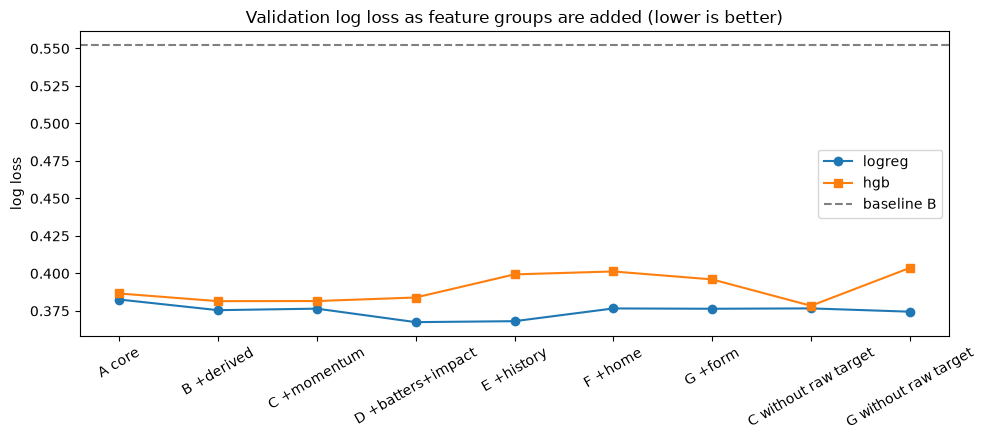

model,hgb,logreg
feature set,,
A core,0.3866,0.3826
B +derived,0.3815,0.3755
C +momentum,0.3816,0.3765
D +batters+impact,0.3839,0.3675
E +history,0.3993,0.3681
F +home,0.4013,0.3766
G +form,0.3960,0.3764
C without raw target,0.3784,0.3767
G without raw target,0.4037,0.3745


In [11]:
def feats(groups, drop=()):
    return [f for g in groups for f in GROUPS[g] if f not in drop]

steps = [("A core", ["core"]), ("B +derived", ["core", "derived"]), ("C +momentum", ["core", "derived", "momentum"]),
         ("D +batters+impact", ["core", "derived", "momentum", "batters", "impact"]),
         ("E +history", ["core", "derived", "momentum", "batters", "impact", "history"]),
         ("F +home", ["core", "derived", "momentum", "batters", "impact", "history", "home"]),
         ("G +form", ["core", "derived", "momentum", "batters", "impact", "history", "home", "form"])]
variants = [(name, feats(g)) for name, g in steps]
variants += [("C without raw target", feats(["core", "derived", "momentum"], drop=["target"])),
             ("G without raw target", feats(list(GROUPS), drop=["target"]))]

rows, ladder_preds = [], {}
for name, fs in variants:
    models = {"logreg": make_logreg(fs, C=best_C), "hgb": make_hgb(**best_hgb_params)}
    for mname, m in models.items():
        p = m.fit(train[fs], y_tr).predict_proba(val[fs])[:, 1]
        ladder_preds[(name, mname)] = p
        rows.append({"feature set": name, "model": mname, "n_features": len(fs), **summarize(y_va, p)})
ladder = pd.DataFrame(rows)
ladder.to_csv(out / "feature_ladder.csv", index=False)

fig, ax = plt.subplots(figsize=(10, 4.5))
for mname, mk in [("logreg", "o"), ("hgb", "s")]:
    d = ladder[ladder.model == mname]
    ax.plot(d["feature set"], d.log_loss, marker=mk, label=mname)
ax.axhline(report(preds).loc[REF, "log_loss"], ls="--", c="gray", label="baseline B")
ax.set(title="Validation log loss as feature groups are added (lower is better)", ylabel="log loss")
ax.tick_params(axis="x", rotation=30); ax.legend()
fig.tight_layout(); fig.savefig(out / "feature_ladder.png", dpi=120); plt.show()
ladder.pivot(index="feature set", columns="model", values="log_loss").round(4).reindex([n for n, _ in variants])

## 12. Choose the final model and feature set

**The rule is fixed in advance:** take the best validation log loss across all (model, feature set) candidates, then pick the *simplest* candidate (fewest features, logistic regression before trees) whose log loss is within `TOL` of the best. A tiny improvement from many extra features isn't worth the risk of overfitting 430 matches.

You can override the choice by setting `FINAL_MODEL` and `FINAL_FEATURE_SET` below (use the names from the ladder). Whatever you pick is written to `model_selection.json`; the final-test notebook will refit exactly that on train + validation.

In [12]:
FINAL_MODEL = None          # None = follow the rule; or "logreg" / "hgb"
FINAL_FEATURE_SET = None    # None = follow the rule; or a name from the ladder, e.g. "C +momentum"

rank = {"logreg": 0, "hgb": 1}
best = ladder.log_loss.min()
cands = (ladder[ladder.log_loss <= best + TOL]
         .assign(r=lambda d: d.model.map(rank)).sort_values(["n_features", "r", "log_loss"]))
pick = cands.iloc[0]
model_name = FINAL_MODEL or pick.model
set_name = FINAL_FEATURE_SET or pick["feature set"]
sel = ladder[(ladder.model == model_name) & (ladder["feature set"] == set_name)].iloc[0]
final_features = dict(variants)[set_name]

print(f"best validation log loss in the ladder: {best:.4f}")
print(f"rule's pick: {pick.model} on '{pick['feature set']}' ({int(pick.n_features)} features, log loss {pick.log_loss:.4f})")
print(f"FINAL: {model_name} on '{set_name}' ({len(final_features)} features, validation log loss {sel.log_loss:.4f})")
print(f"baseline B validation log loss: {report(preds).loc[REF, 'log_loss']:.4f}")

selection = {
    "model": model_name,
    "feature_set": set_name,
    "features": final_features,
    "params": {"C": float(best_C)} if model_name == "logreg" else {k: (float(v) if isinstance(v, float) else int(v)) for k, v in best_hgb_params.items()},
    "validation_log_loss": float(sel.log_loss),
    "selection_rule": f"simplest candidate within {TOL} of the best validation log loss" if not (FINAL_MODEL or FINAL_FEATURE_SET) else "manual override",
    "train_seasons": [int(train.season.min()), int(train.season.max())],
    "validation_seasons": [int(val.season.min()), int(val.season.max())],
}
(out / "model_selection.json").write_text(json.dumps(selection, indent=2))

keep = {**preds, **{f"{k[1]} | {k[0]}": v for k, v in ladder_preds.items() if k == (set_name, model_name)}}
pd.concat([val[["match_id", "over", LABEL]].reset_index(drop=True), pd.DataFrame(keep)], axis=1).to_csv(out / "val_predictions.csv", index=False)
print("saved model_selection.json, val_predictions.csv and the tables to", out.resolve())

best validation log loss in the ladder: 0.3675
rule's pick: logreg on 'D +batters+impact' (20 features, log loss 0.3675)
FINAL: logreg on 'D +batters+impact' (20 features, validation log loss 0.3675)
baseline B validation log loss: 0.5522
saved model_selection.json, val_predictions.csv and the tables to C:\Users\LEGION\OneDrive\Documents\GitHub\es335-2026\results


## 13. What to write down

- The baseline numbers (A, A2, B) and how much the models improve on B, with the bootstrap intervals. If an interval for the difference includes 0, say the improvement is not clearly separable from noise with only ~70 validation matches.
- Whether logistic regression or boosted trees won, whether monotonic constraints and the neural network helped, and whether recalibration changed anything.
- Which feature groups helped on validation and which did not. "Adding venue, batters, home and form didn't help" is a valid, reportable finding.
- The calibration plot and the by-over plot, with a sentence on where the models are least reliable (early overs, or states unlike the training seasons).
- The scoring-level shift: did dropping raw `target` change anything?

**Next notebook: 04 - final test.** Refit the chosen configuration on train + validation, evaluate **once** on the test seasons, add match-bootstrap intervals, and do the error analysis. Don't open the test file before then.